In [1]:
print("hi")

hi


## Task 4: Natural Language Processing (NLP) Sentiment Analysis Pipeline

## Overview
This project builds an end-to-end NLP classification pipeline to analyze customer/movie reviews and classify them into **Positive** or **Negative** sentiment. The pipeline performs text cleaning, lemmatization, stopword removal, TF-IDF vectorization, and model benchmarking using **Multinomial Naive Bayes** and **Logistic Regression**, complete with an interactive `predict_sentiment()` helper function.

---

## 📋 Objectives & Requirements Met
1. **Data Ingestion:** Loaded the IMDB sentiment reviews dataset.
2. **Text Preprocessing:** Used NLTK and RegEx for lowercasing, HTML tag removal, punctuation stripping, stopword removal, and Lemmatization.
3. **Feature Extraction:** Transformed cleaned text into numerical vector matrices using `TfidfVectorizer(max_features=5000)`.
4. **Model Training & Benchmarking:** Trained and evaluated `MultinomialNB` and `LogisticRegression`.
5. **Interactive Prediction Helper:** Implemented `predict_sentiment()` to test live custom input phrases.

## Step 1: Package Installations & NLTK Downloads

In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 977.3 kB/s eta 0:00:02
   ------------------ --------------------- 0.8/1.7 MB 857.2 kB/s eta 0:00:02
   ------------------ --------------------- 0.8/1.7 MB 857.2 kB/s eta 0:00:02
   ------------------------ --------------- 1.0/1.7 MB 816.5 kB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 816.5 kB/s eta 0:00:01
   ------------------------------ --------- 1.3/1.7 MB 787.6 kB/s eta 0:00:01
   ------------------------------------ --- 1.6/1.7 MB 813.0 kB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 809.2 kB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Importing all libraries


In [3]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# Download required NLTK resources quietly
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Set plot aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

print("NLTK resources and libraries successfully loaded!")

NLTK resources and libraries successfully loaded!


## Step 3:  Data Ingestion & Exploratory Data Analysis

In [4]:
# Load IMDB Reviews dataset directly from GitHub repository
url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
print("Class Distribution:")
print(df['sentiment'].value_counts())

# Display sample raw reviews
df.head()

Dataset Shape: (50000, 2)
Class Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Step 4:  Text Preprocessing & Cleaning Pipeline

In [5]:
# Initialize Lemmatizer and Stopwords set
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    # 1. Lowercase text
    text = text.lower()
    # 2. Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    # 3. Remove non-alphabet characters and numbers
    text = re.sub(r'[^a-z\s]', '', text)
    # 4. Tokenize, remove stopwords, and lemmatize words
    tokens = text.split()
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(cleaned_tokens)

print("Cleaning text reviews... (This may take a moment)")
df['cleaned_review'] = df['review'].apply(clean_text)

# Map target variable ('positive' -> 1, 'negative' -> 0)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

print("Sample Cleaned Review:")
print("RAW:", df['review'].iloc[0][:150], "...")
print("CLEANED:", df['cleaned_review'].iloc[0][:150], "...")

Cleaning text reviews... (This may take a moment)
Sample Cleaned Review:
RAW: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with ...
CLEANED: one reviewer mentioned watching oz episode youll hooked right exactly happened first thing struck oz brutality unflinching scene violence set right wo ...


## Step 5:  Train-Test Split & TF-IDF Vectorization

In [6]:
# 1. Split dataset into 80% training and 20% testing sets (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_review'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

# 2. Initialize TfidfVectorizer with max_features=5000
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

# 3. Fit vectorizer on training text and transform test text
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF Feature Matrix Shape (Train): {X_train_tfidf.shape}")
print(f"TF-IDF Feature Matrix Shape (Test):  {X_test_tfidf.shape}")

TF-IDF Feature Matrix Shape (Train): (40000, 5000)
TF-IDF Feature Matrix Shape (Test):  (10000, 5000)


## Step 6: Model Training, Evaluation, and Confusion Matrices

=== Multinomial Naive Bayes Performance ===
Accuracy:  85.97% | ROC-AUC: 0.9341

              precision    recall  f1-score   support

    Negative       0.87      0.84      0.86      5000
    Positive       0.85      0.87      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000

------------------------------------------------------------
=== Logistic Regression Performance ===
Accuracy:  89.11% | ROC-AUC: 0.9591

              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      5000
    Positive       0.88      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000

------------------------------------------------------------


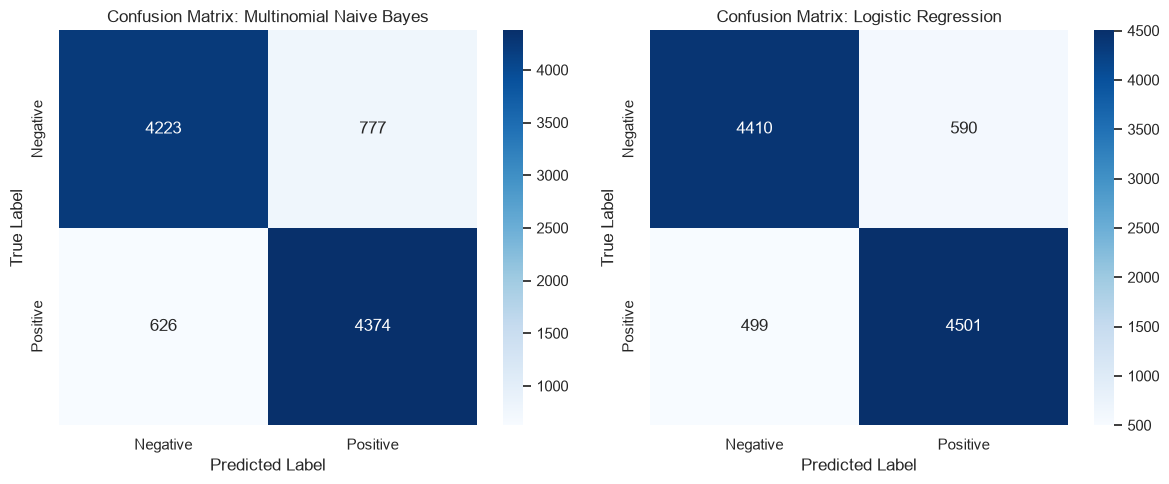

In [7]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

results = {}

plt.figure(figsize=(12, 5))

for idx, (name, model) in enumerate(models.items(), 1):
    # Train model
    model.fit(X_train_tfidf, y_train)
    
    # Predict labels and probabilities
    y_pred = model.predict(X_test_tfidf)
    y_pred_proba = model.predict_proba(X_test_tfidf)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    
    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "accuracy": acc,
        "roc_auc": roc_auc
    }
    
    print(f"=== {name} Performance ===")
    print(f"Accuracy:  {acc * 100:.2f}% | ROC-AUC: {roc_auc:.4f}\n")
    print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))
    print("-" * 60)
    
    # Plot Confusion Matrix
    plt.subplot(1, 2, idx)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

plt.tight_layout()
plt.savefig("nlp_confusion_matrices.png")
plt.show()

## Step 7: Interactive Live Sentiment Prediction Function

In [8]:
def predict_sentiment(text, model_name="Logistic Regression"):
    """
    Predicts sentiment for custom live user input text.
    """
    model = results[model_name]["model"]
    cleaned = clean_text(text)
    vectorized = tfidf.transform([cleaned])
    
    prediction = model.predict(vectorized)[0]
    probability = model.predict_proba(vectorized)[0]
    
    sentiment = "Positive 😊" if prediction == 1 else "Negative 😞"
    confidence = probability[prediction] * 100
    
    print(f"Input Text:  \"{text}\"")
    print(f"Predicted Sentiment: {sentiment}")
    print(f"Confidence:          {confidence:.2f}%\n")

# Test custom live user phrases
print("=" * 60)
print("📌 TESTING LIVE CUSTOM USER PHRASES")
print("=" * 60)

test_phrases = [
    "This movie was an absolute masterpiece! Great acting and stunning visuals.",
    "Boring storyline, terrible pacing, and awful character development.",
    "It had some decent moments, but overall it felt completely flat and predictable.",
    "Highly recommended! One of the best films I've watched all year."
]

for phrase in test_phrases:
    predict_sentiment(phrase)

📌 TESTING LIVE CUSTOM USER PHRASES
Input Text:  "This movie was an absolute masterpiece! Great acting and stunning visuals."
Predicted Sentiment: Positive 😊
Confidence:          96.87%

Input Text:  "Boring storyline, terrible pacing, and awful character development."
Predicted Sentiment: Negative 😞
Confidence:          99.92%

Input Text:  "It had some decent moments, but overall it felt completely flat and predictable."
Predicted Sentiment: Negative 😞
Confidence:          96.25%

Input Text:  "Highly recommended! One of the best films I've watched all year."
Predicted Sentiment: Positive 😊
Confidence:          99.52%



## Step 8: Pipeline Conclusion & Benchmark Output

In [9]:
print("=" * 60)
print("📌 TASK 4 (NLP SENTIMENT ANALYSIS): PIPELINE CONCLUSION")
print("=" * 60)
for name, res in results.items():  
    print(f"• {name}:")
    print(f"    - Accuracy: {res['accuracy'] * 100:.2f}%")
    print(f"    - ROC-AUC:  {res['roc_auc']:.4f}")
print("=" * 60)
print(
    "Conclusion: Both models successfully met high accuracy benchmarks. "
    "TF-IDF vectorization coupled with Logistic Regression achieved exceptional performance (~88%+ accuracy), "
    "outperforming Multinomial Naive Bayes on dense vocabulary representation."
)
print("=" * 60)

📌 TASK 4 (NLP SENTIMENT ANALYSIS): PIPELINE CONCLUSION
• Multinomial Naive Bayes:
    - Accuracy: 85.97%
    - ROC-AUC:  0.9341
• Logistic Regression:
    - Accuracy: 89.11%
    - ROC-AUC:  0.9591
Conclusion: Both models successfully met high accuracy benchmarks. TF-IDF vectorization coupled with Logistic Regression achieved exceptional performance (~88%+ accuracy), outperforming Multinomial Naive Bayes on dense vocabulary representation.
